In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [14]:
df = pd.read_csv('noisy_curvefit_data.csv')
print(df)

           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0  -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1  -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2  -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3  -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4  -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
..       ...        ...        ...        ...        ...        ...
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850

[100 rows x 6 columns]


In [15]:
print(df.shape)

(100, 6)


In [16]:
rows, cols = df.shape
print(rows)
print(cols)

100
6


In [17]:
print(df.head())
print(df.tail())

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


In [18]:
print(df.columns.tolist())

['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']


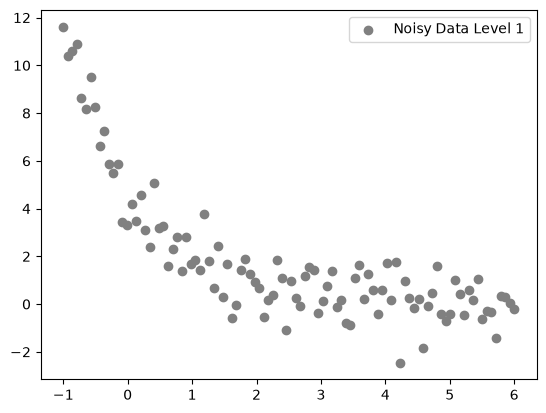

In [19]:
plt.scatter(
    df['x'], df['y_noise_1'], color = 'gray', label = 'Noisy Data Level 1',
)
plt.xlabel = ('x')
plt.ylabel = ('y')
plt.title = ('x vs. y_noise_1')
plt.legend()

plt.show()

## 2.2

In [20]:
x = df['x'].values
y_noise_1 = df['y_noise_1'].values

Fit: y = 4.71 * e^(-0.92 * x)


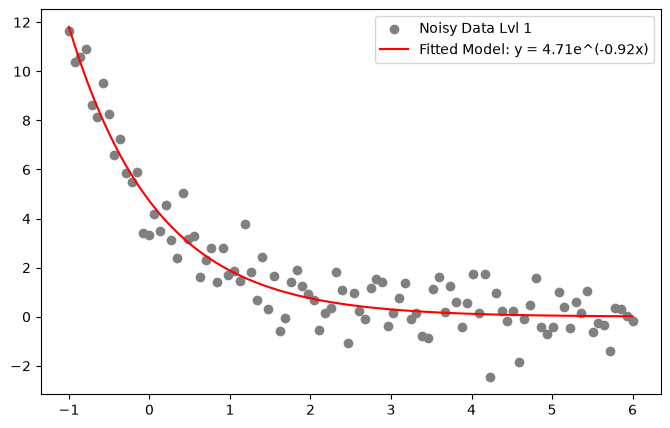

In [28]:
def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt
print(f'Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)')

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

plt.figure(figsize=(8, 5))

sort_idx = np.argsort(x)
x_sorted = x[sort_idx]

plt.scatter(x, y_noise_1, color = 'gray', label = 'Noisy Data Lvl 1')

plt.plot(
    x_sorted,
    model(x_sorted, A_fit, k_fit),
    color = 'red',
    label = f'Fitted Model: y = {A_fit:.2f}e^(-{k_fit:.2f}x)',
)

plt.legend()
plt.show()

## 2.3

Noise Lvl 2 | Fit: y = 4.81 * e^(-0.89 * xReduced chi2: 2.83
Noise Lvl 3 | Fit: y = 5.30 * e^(-0.85 * xReduced chi2: 9.03
Noise Lvl 4 | Fit: y = 4.52 * e^(-0.91 * xReduced chi2: 18.64
Noise Lvl 5 | Fit: y = 3.47 * e^(-1.17 * xReduced chi2: 26.80


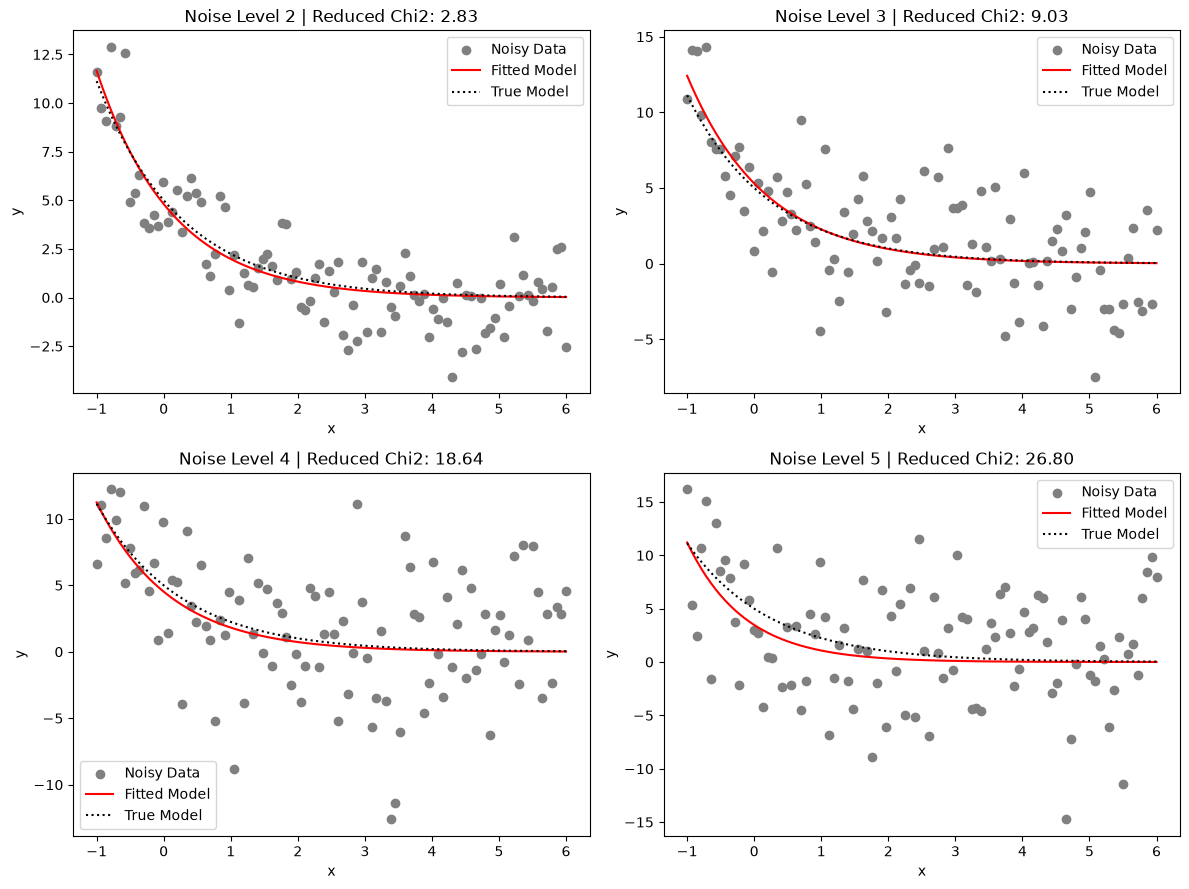

In [36]:
def fit_model(x, y):
    p0 = [1, 1]
    popt, pcov = curve_fit(model, x, y, p0=p0)

    residuals = y - model(x, *popt)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

y_true = model(x, 5, 0.8)
y_noise_2 = y_true + np.random.normal(0, 2, len(x))
y_noise_3 = y_true + np.random.normal(0, 3, len(x))
y_noise_4 = y_true + np.random.normal(0, 4, len(x))
y_noise_5 = y_true + np.random.normal(0, 5, len(x))

datasets = [y_noise_2, y_noise_3, y_noise_4, y_noise_5]
noise_levels = [2, 3, 4, 5]

for ax, y_data, level in zip(axes, datasets, noise_levels):
    popt, chi2_red = fit_model(x, y_data)
    A_fit, k_fit = popt
    print(
        f"Noise Lvl {level} | Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x"
        f"Reduced chi2: {chi2_red:.2f}"
    )
    ax.scatter(x, y_data, color = "gray", label = "Noisy Data")
    ax.plot(x, model(x, A_fit, k_fit), color = "red", label = "Fitted Model")
    ax.plot(
        x,
        model(x, 5, 0.8),
        color = "black",
        linestyle = ":",
        label = "True Model",
    )
    ax.set_title(f"Noise Level {level} | Reduced Chi2: {chi2_red:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()

In [41]:
all_data = [y_noise_1, y_noise_2, y_noise_3, y_noise_4, y_noise_5]
results = []

for level, y_data in zip(noise_levels, all_data):
    popt, chi2_red = fit_model(x, y_data)
    A_fit, k_fit = popt

    results.append({
        "Noise Level": level,
        "A fit": A_fit,
        "k fit": k_fit,
        "Reduced chi2": chi2_red
    })

df = pd.DataFrame(results)
print(df)

df.to_csv("noisy_parameters.csv", index=False)

   Noise Level     A fit     k fit  Reduced chi2
0            2  4.714814  0.918308      0.790673
1            3  4.805301  0.885907      2.825765
2            4  5.304169  0.850621      9.034557
3            5  4.519672  0.910511     18.641930
